In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib as mpl
from tqdm import tqdm
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import fcluster,linkage
from TiVy import *
%matplotlib inline

## 1. Load the data
Please download the dataset from https://www.kaggle.com/datasets/shayanfazeli/heartbeat


In [3]:
# Please download the dataset from https://www.kaggle.com/datasets/shayanfazeli/heartbeat
df = pd.concat((pd.read_csv('mitbih_train.csv', header=None),pd.read_csv('mitbih_test.csv', header=None)))
ts = df.iloc[:,:-1]
labels = df.iloc[:,-1]
ts = ts.iloc[:,:180].to_numpy()
print(f"Size of time series: {ts.shape}")

Size of time series: (109446, 180)


## 2. Extract the time series summary on 100,000 time series

In [4]:
time_now = time.time()
tivy = TiVy(chunk_size=18,strength=1,use_LSH=True, nPerm=4, bandWidth=1)
tivy.cluster_subsequences(ts)
print(f"Time taken: {time.time() - time_now}")

# eg.clusters_combinations[0]

Time taken: 0.8405930995941162


## 3. Output the data for visualization

In [5]:
labels_tag = {0:'N', 1:'SVEB', 2:'VEB', 3:'F',  4:'Q'}
scan_profile = tivy.prefix_scan(tivy.clusters,tivy.ts_start,minlen=10)
counter = scan_profile['counter']
sequenceClusterDB = scan_profile['sequenceClusterDB']
clusters = tivy.optimize_patterns(sequenceClusterDB,counter,minSupport=100,minLength=100,minSize=500,labels=labels.astype(int).apply(lambda x: labels_tag[x]))
result = tivy.output_result(clusters,return_idx=True)


In [6]:
len(clusters)

12

## 4. Prepare the buffer for visualization

In [7]:
from TSVis.widget import TimeSeriesVis
time_now = time.time()
summary = TimeSeriesVis(n_cols=6,padding=50,n_ticks=3,chart_width=140,chart_height=70,interpolate=100)
summary.fit(result['result'],central_line=result['center_line'],labels=result['labels'],labels_order=['N','SVEB','VEB','F','Q'])
print(f"Time taken: {time.time() - time_now}")

Preparing Buffer...


  0%|          | 0/12 [00:00<?, ?it/s]

Time taken: 15.77445101737976


## 5. Visualize the clusters

Box(children=(Label(value='Show Lines'), Checkbox(value=False, description='|', indent=False, layout=Layout(wi…

RFBOutputContext()

CanvasBackend(css_height='600px', css_width='1140px')
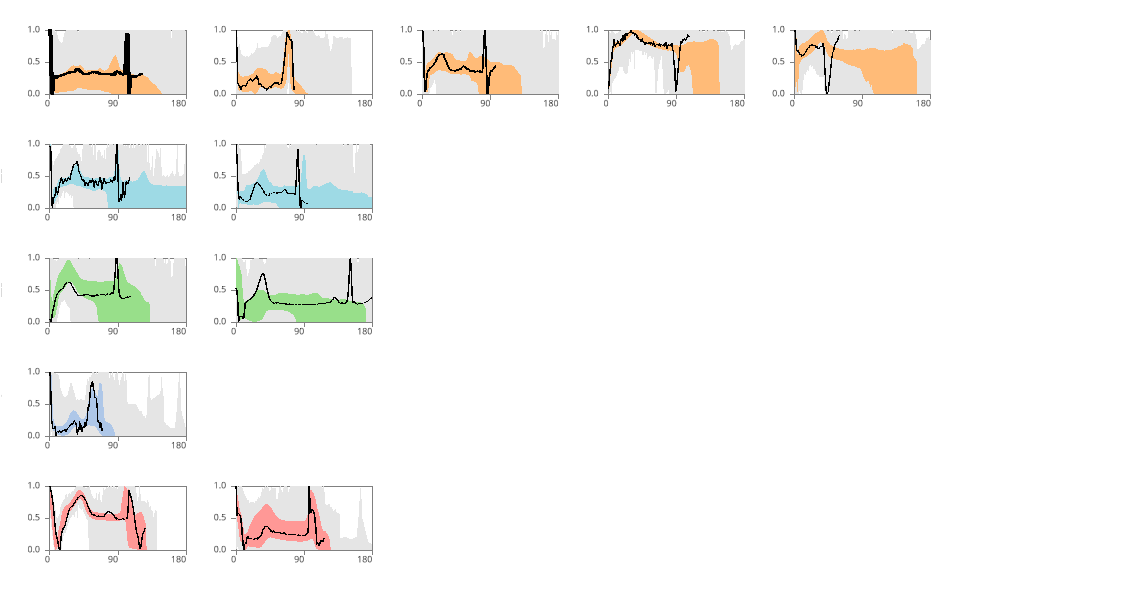

In [8]:
summary.visualize()

In [9]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
